[*********************100%***********************]  1 of 1 completed


Original DataFrame columns:
MultiIndex([( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])

Modified DataFrame columns:
Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='str')
Epoch 1 | Loss: 16.3763
Epoch 2 | Loss: 16.0143
Epoch 3 | Loss: 16.0105
Epoch 4 | Loss: 16.0252
Epoch 5 | Loss: 15.9970
Epoch 6 | Loss: 15.9745
Epoch 7 | Loss: 15.9456
Epoch 8 | Loss: 15.9088
Epoch 9 | Loss: 15.9214
Epoch 10 | Loss: 15.9798
Epoch 11 | Loss: 15.9777
Epoch 12 | Loss: 15.9083
Epoch 13 | Loss: 15.8891
Epoch 14 | Loss: 15.8352
Epoch 15 | Loss: 15.8018
Epoch 16 | Loss: 15.7726
Epoch 17 | Loss: 15.7397
Epoch 18 | Loss: 15.8690
Epoch 19 | Loss: 15.7763
Epoch 20 | Loss: 15.8154

✅ Best Threshold: 0.50
Entry signal length: 179
Close prices length: 180

===== TRADING PERFORMANCE METRICS =====
Total Return: 6.57%
CAGR: 9.43%
Sharpe Ratio: 3.44
Maximum Drawdown: 1.20%


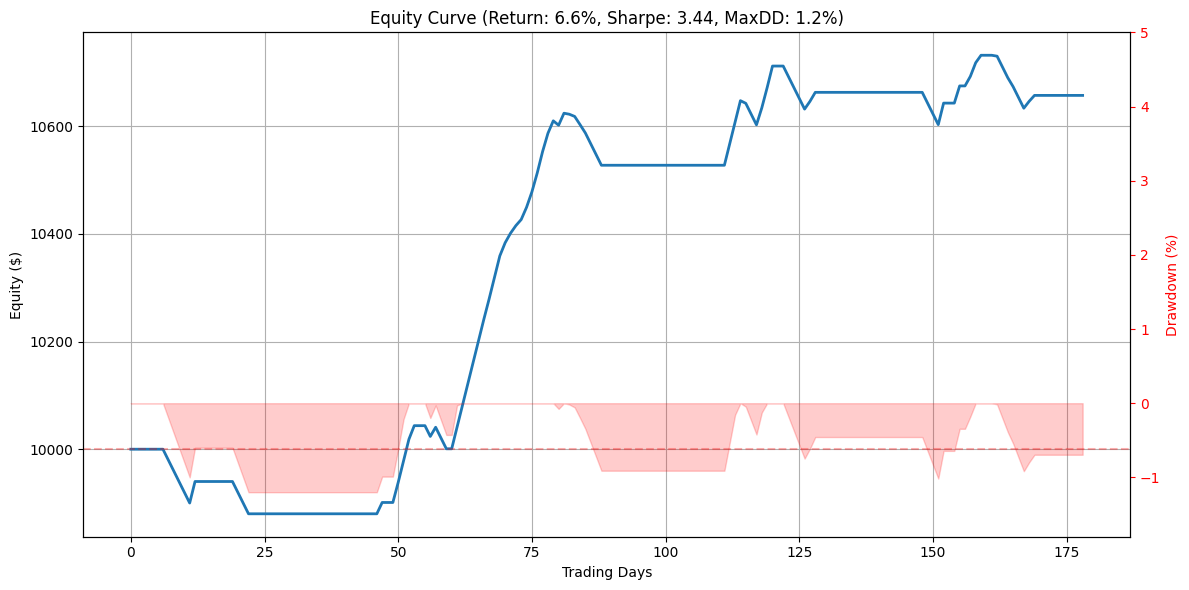

In [5]:
import yfinance as yf
import pandas as pd
import numpy as np
import ta
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt

df = yf.download("AAPL", start="2023-01-01", end="2026-12-31")

print("Original DataFrame columns:")
print(df.columns)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = [col[0] if len(col) > 0 else col for col in df.columns]

print("\nModified DataFrame columns:")
print(df.columns)

df['Return'] = np.log(df['Close'] / df['Close'].shift(1))
df['Momentum'] = df['Close'] - df['Close'].rolling(window=5).mean()

df['RSI'] = ta.momentum.RSIIndicator(close=df['Close'], window=14).rsi()
df['MACD_diff'] = ta.trend.MACD(close=df['Close']).macd_diff()
df = df.dropna()

features = df[['Return', 'Momentum', 'RSI', 'MACD_diff']].values
targets = (df['Close'].shift(-1) > df['Close']).astype(int).iloc[:-1]
features = features[:-1]

def create_sequences(X, y, seq_len):
    Xs, ys = [], []
    for i in range(len(X) - seq_len):
        Xs.append(X[i:i+seq_len])
        ys.append(y[i+seq_len])
    return np.array(Xs), np.array(ys)

SEQ_LEN = 20
X_seq, y_seq = create_sequences(features, targets.values, SEQ_LEN)

class StockDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, test_size=0.2, shuffle=False)
train_ds = StockDataset(X_train, y_train)
test_ds = StockDataset(X_test, y_test)
train_loader = DataLoader(train_ds, batch_size=32)
test_loader = DataLoader(test_ds, batch_size=32)

class TransformerBinaryClassifier(nn.Module):
    def __init__(self, input_dim, seq_len, d_model=32, nhead=4, num_layers=2):
        super().__init__()
        self.embedding = nn.Linear(input_dim, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Sequential(
            nn.Linear(d_model * seq_len, 64), nn.ReLU(),
            nn.Linear(64, 1), nn.Sigmoid()
        )

    def forward(self, x):
        x = self.embedding(x)
        x = self.transformer(x)
        return self.fc_out(x.reshape(x.size(0), -1))

model = TransformerBinaryClassifier(input_dim=4, seq_len=SEQ_LEN)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(20):
    model.train(); total_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward(); optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1} | Loss: {total_loss:.4f}")

model.eval(); all_probs, all_labels = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        probs = model(X_batch)
        all_probs.extend(probs.numpy().flatten())
        all_labels.extend(y_batch.numpy().flatten())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

thresholds = [0.5, 0.6, 0.7, 0.8]
best_f1, best_threshold = 0, 0.5
for t in thresholds:
    preds = (all_probs > t).astype(int)
    report = classification_report(all_labels, preds, output_dict=True, zero_division=0)
    f1 = report.get('1', {}).get('f1-score', 0)
    if f1 > best_f1:
        best_f1, best_threshold = f1, t
print(f"\n✅ Best Threshold: {best_threshold:.2f}")

X_test_flat = X_test[:, -1, :]  # last timestep only
rsi = X_test_flat[:, 2]
macd = X_test_flat[:, 3]
entry_signal = (all_probs > best_threshold) & (rsi > 50) & (macd > 0)

initial_cash = 10000
cash = initial_cash
position_size = 1000
sl_pct, tp_pct = -0.02, 0.04
equity_curve = [cash]

test_start_idx = len(df) - len(entry_signal) - 1  # -1 for the shift in target
close_prices = df['Close'].values[test_start_idx:]

print(f"Entry signal length: {len(entry_signal)}")
print(f"Close prices length: {len(close_prices)}")

for i in range(len(entry_signal)-1):
    if entry_signal[i]:
        buy_price = close_prices[i+1]  # Buy next day's close
        position_active = True
        for j in range(1, 6):  # Simulate 5-day holding window
            if i + j + 1 >= len(close_prices):
                position_active = False
                cash += position_size * ((close_prices[-1] - buy_price) / buy_price)
                break

            pct_change = (close_prices[i+j+1] - buy_price) / buy_price

            if pct_change >= tp_pct:
                cash += position_size * tp_pct
                position_active = False
                break
            elif pct_change <= sl_pct:
                cash += position_size * sl_pct
                position_active = False
                break

        if position_active and i + 5 + 1 < len(close_prices):
            final_pct_change = (close_prices[i+5+1] - buy_price) / buy_price
            cash += position_size * final_pct_change

    equity_curve.append(cash)

equity_array = np.array(equity_curve)

final_value = equity_array[-1]
initial_value = equity_array[0]
total_return = ((final_value / initial_value) - 1) * 100

n_days = len(equity_array) - 1
n_years = n_days / 252
cagr = (((final_value / initial_value) ** (1 / n_years)) - 1) * 100 if n_years > 0 else 0

daily_returns = np.diff(equity_array) / equity_array[:-1]
sharpe_ratio = np.mean(daily_returns) / np.std(daily_returns) * np.sqrt(252) if np.std(daily_returns) > 0 else 0

peak = np.maximum.accumulate(equity_array)
drawdown = (equity_array - peak) / peak * 100
max_drawdown = abs(drawdown.min())

trade_indices = np.where(entry_signal)[0]
wins = 0
total_trades = len(trade_indices)

for i in trade_indices:
    if i + 1 < len(close_prices):
        buy_price = close_prices[i+1]
        for j in range(1, 6):
            if i + j + 1 >= len(close_prices):
                break
            pct_change = (close_prices[i+j+1] - buy_price) / buy_price
            if pct_change >= tp_pct:
                wins += 1
                break
            elif pct_change <= sl_pct:
                break
        else:
            if i + 5 + 1 < len(close_prices):
                final_pct_change = (close_prices[i+5+1] - buy_price) / buy_price
                if final_pct_change > 0:
                    wins += 1

win_rate = (wins / total_trades * 100) if total_trades > 0 else 0

print("\n===== TRADING PERFORMANCE METRICS =====")
print(f"Total Return: {total_return:.2f}%")
print(f"CAGR: {cagr:.2f}%")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")
print(f"Maximum Drawdown: {max_drawdown:.2f}%")
print(f"Win Rate: {win_rate:.2f}%")
print(f"Total Trades: {total_trades}")
print(f"Winning Trades: {wins}")
print("=======================================")

plt.figure(figsize=(12, 6))
plt.plot(equity_array, linewidth=2)
plt.title(f"Equity Curve (Return: {total_return:.1f}%, Sharpe: {sharpe_ratio:.2f}, MaxDD: {max_drawdown:.1f}%)")
plt.xlabel("Trading Days")
plt.ylabel("Equity ($)")
plt.grid(True)

plt.axhline(y=initial_cash, color='r', linestyle='--', alpha=0.3)

ax2 = plt.gca().twinx()
ax2.fill_between(range(len(drawdown)), drawdown, 0, color='red', alpha=0.2)
ax2.set_ylabel('Drawdown (%)', color='red')
ax2.tick_params(axis='y', colors='red')
ax2.set_ylim(min(drawdown) * 1.5, 5)

plt.tight_layout()
plt.show()
